# Graph construction
This notebook describes the bipartite graph construction.

In [2]:
from json import encoder

import networkx as nx
import pandas as pd
import numpy as np

In [3]:
# JSON_STRUCTURE_PATH = "selected_category_docs/{doc_id}.json"
JSON_STRUCTURE_PATH = "document_data_parsing/{doc_id}.json"

In [4]:
paragraph_dataset_mini = [
    "116062204", "116075685", "116080900", "116084352", "116084886", "116099338", "116102314", "116105977", "116106432", "116109598", "116110555", "116116081", "116118921", "116120654", "116121714", "116125191", "116126076", "116127831", "116141779", "116142769", "116149190", "116150283", "116167789", "116168634", "116170057", "116170822", "116192026", "116194637", "116196887", "116197578", "116199866", "116204676", "116213690", "116214232", "116220471", "116221948", "116226431", "116229939", "116232414", "116233794", "116245112", "116246991", "116248468", "116252607", "116253514", "116256069", "116257159", "116259036", "116260246", "116261015", "116261263", "116270112", "116277632", "116278949", "116283678", "116285648", "116289180", "116308208", "116310154", "116320626", "116321603", "116336690", "116339406", "116344031", "116350541", "116350825", "116358099", "116359089", "116376162", "116377931", "116385451", "116398308", "116410200", "116410462", "116414218", "116432495", "116434259", "116442566", "116462199", "116588653", "116681882", "116764649", "116780853", "116790074", "116794466", "116972204", "117069850", "117125134", "117130242", "117230819", "117251852", "117420480", "117440182", "117456818", "117460145", "117464049", "117489745", "117516936", "117556435"
]

In [5]:
from pathlib import Path
import json

In [6]:
def read_json_file(path: str):
    with open(path, "r") as doc_file:
        doc_file_contents = json.loads(doc_file.read())

    return doc_file_contents

In [7]:
def read_structures(doc_list: list[str]) -> dict:
    docs = {}
    for doc_id in doc_list:
        doc_path = JSON_STRUCTURE_PATH.format(doc_id=doc_id)
        doc_json_contents = read_json_file(doc_path)
        docs[doc_id] = doc_json_contents

    return docs

In [8]:
doc_args = read_structures(paragraph_dataset_mini)
len(doc_args)

99

In [9]:
doc_args

{'116062204': {'document_id': '116062204',
  'result': {'components': [{'id': 'P17',
     'type': 'PREMISE',
     'argumentative_role': 'BASE_PREMISE',
     'source_span': {'text': 'Відповідно до витягу з наказу військової частини НОМЕР_1 (по стройовій частині) від 06.04.2023 №96 ОСОБА_5 , було зараховано в списки особового складу військової частини, поставлено на посаду водія взводу протитанкових керованих ракет роти протитанкових ракетних комплексів.',
      'paragraph_id': 17,
      'start_char': None,
      'end_char': None},
     'section': 'Встановлені судом обставини',
     'support_status': None},
    {'id': 'P18',
     'type': 'PREMISE',
     'argumentative_role': 'BASE_PREMISE',
     'source_span': {'text': 'Відповідно до витягу з наказу військової частини НОМЕР_2 (по стройовій частині) від 22.08.2023 №315 ОСОБА_6 , було зараховано в списки особового складу військової частини, поставлено на посаду номера гранатометника 2 механізованого відділення 3 механізованого взводу 2 мех

## Extracting premises and conclusions from the doc structure


In [10]:
import jsonpath

In [11]:
def compose_dataframe(doc_dict: dict[str, dict]):
    df = pd.DataFrame(columns=["doc_id", "arg_id", "arg_text", "arg_type", "arg_argtype"])
    for doc_id, doc_contents in doc_dict.items():
        doc_df_dict = {}
        orig_arg_id = jsonpath.findall("$.result.components[*].id", doc_contents)
        orig_arg_text = jsonpath.findall("$.result.components[*].source_span.text", doc_contents)
        orig_arg_type = jsonpath.findall("$.result.components[*].type", doc_contents)
        orig_arg_argtype = jsonpath.findall("$.result.components[*].argumentative_role", doc_contents)

        assert len(orig_arg_text) == len(orig_arg_type) == len(orig_arg_argtype)
        doc_id_list = [doc_id for _ in range(len(orig_arg_text))]

        doc_df_dict["doc_id"] = doc_id_list
        doc_df_dict["arg_id"] = orig_arg_id
        doc_df_dict["arg_text"] = orig_arg_text
        doc_df_dict["arg_type"] = orig_arg_type
        doc_df_dict["arg_argtype"] = orig_arg_argtype
        df = pd.concat([df, pd.DataFrame(doc_df_dict)])

    return df

In [12]:
arguments_df = compose_dataframe(doc_args)
arguments_df.head()

,doc_id,arg_id,arg_text,arg_type,arg_argtype
0,116062204,P17,Відповідно до витягу з наказу військової части...,PREMISE,BASE_PREMISE
1,116062204,P18,Відповідно до витягу з наказу військової части...,PREMISE,BASE_PREMISE
2,116062204,P19,"Згідно зі ст.ст. 11, 16, 49 Статуту внутрішньо...",PREMISE,BASE_PREMISE
3,116062204,P20,"Відповідно до ст.ст. 1, 4, 6 Дисциплінарного с...",PREMISE,BASE_PREMISE
4,116062204,C21,"Проте, рядовий ОСОБА_5 та молодший сержант ОСО...",CLAIM,INTERMEDIATE_CONCLUSION


## Extracting edges from the document

In [16]:
def compose_relations_df(doc_dict: dict[str, dict]):
    df = pd.DataFrame(columns=["doc_id", "rel_id", "source", "target", "relation", "support_structure", "confidence", "justification"])
    for doc_id, doc_contents in doc_dict.items():
        relation_id = jsonpath.findall("$.result.relations[*].id", doc_contents)
        relation_source = jsonpath.findall("$.result.relations[*].source", doc_contents)
        relation_target = jsonpath.findall("$.result.relations[*].target", doc_contents)
        relation_relation = jsonpath.findall("$.result.relations[*].relation", doc_contents)
        relation_support = jsonpath.findall("$.result.relations[*].support_structure", doc_contents)
        relation_confidence = jsonpath.findall("$.result.relations[*].confidence", doc_contents)
        relation_justification = jsonpath.findall("$.result.relations[*].justification", doc_contents)

        relations_df_dict = {
            "doc_id": [doc_id for _ in range(len(relation_id))],
            "rel_id": relation_id,
            "source": relation_source,
            "target": relation_target,
            "relation": relation_relation,
            "support_structure": relation_support,
            "confidence": relation_confidence,
            "justification": relation_justification,
        }
        df = pd.concat([df, pd.DataFrame(relations_df_dict)])

    return df

In [17]:
relations_df = compose_relations_df(doc_args)

In [18]:
relations_df.head()

,doc_id,rel_id,source,target,relation,support_structure,confidence,justification
0,116062204,E01,P23,C26,SUPPORT,CONVERGENT,0.9,Опис дій обвинувачених у період воєнного стану...
1,116062204,E02,P24,C26,SUPPORT,CONVERGENT,0.95,Детальний опис таємного викрадення майна є фак...
2,116062204,E03,C21,C26,SUPPORT,CONVERGENT,0.78,Висновок про умисний характер дій та порушення...
3,116062204,E04,P28a,C37,SUPPORT,CONVERGENT,0.86,Визнання вини та пояснення обставин ОСОБА_5 пі...
4,116062204,E05,P30a,C37,SUPPORT,CONVERGENT,0.86,Визнання вини та пояснення обставин ОСОБА_6 пі...


## Graph construction

In [19]:
import matplotlib.pyplot as plt

In [20]:
relations_df["doc_id"].unique(), arguments_df["doc_id"].unique()

(array(['116062204', '116075685', '116080900', '116084352', '116084886',
        '116099338', '116102314', '116105977', '116106432', '116109598',
        '116110555', '116116081', '116118921', '116120654', '116121714',
        '116125191', '116126076', '116127831', '116141779', '116142769',
        '116149190', '116167789', '116168634', '116170057', '116170822',
        '116192026', '116194637', '116196887', '116197578', '116199866',
        '116204676', '116213690', '116214232', '116220471', '116221948',
        '116226431', '116229939', '116232414', '116233794', '116245112',
        '116246991', '116248468', '116252607', '116253514', '116256069',
        '116257159', '116259036', '116260246', '116261015', '116261263',
        '116277632', '116278949', '116283678', '116285648', '116289180',
        '116308208', '116310154', '116320626', '116321603', '116336690',
        '116339406', '116344031', '116350541', '116350825', '116358099',
        '116359089', '116376162', '116377931', '116

In [21]:
arg_sampled_df = arguments_df[arguments_df["doc_id"] == "109073157"]
rel_sampled_df = relations_df[relations_df["doc_id"] == "109073157"]
arg_sampled_df, rel_sampled_df

(Empty DataFrame
 Columns: [doc_id, arg_id, arg_text, arg_type, arg_argtype]
 Index: [],
 Empty DataFrame
 Columns: [doc_id, rel_id, source, target, relation, support_structure, confidence, justification]
 Index: [])

In [22]:
bi_legal_G = nx.DiGraph()

for row in arg_sampled_df.itertuples(index=False):
    bi_legal_G.add_node(
        row.arg_id,
        arg_type=row.arg_type,
        argumentative_role=row.arg_argtype,
        text=row.arg_text,
    )

for row in rel_sampled_df.itertuples(index=False):
    bi_legal_G.add_edge(
        row.source,
        row.target,
        relation=row.relation,
        confidence=float(row.confidence),
    )

In [23]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def _hierarchical_layout(graph):
    positions = {}
    y_offset = 0.0
    components = sorted(nx.weakly_connected_components(graph), key=len, reverse=True)

    for component_nodes in components:
        component = graph.subgraph(component_nodes)
        if nx.is_directed_acyclic_graph(component):
            levels = [list(level) for level in nx.topological_generations(component)]
        else:
            levels = [list(component.nodes)]

        component_height = max(len(level) for level in levels)
        component_center = y_offset + (component_height - 1) / 2

        for depth, level in enumerate(levels):
            y_values = (
                np.linspace(y_offset, y_offset + component_height - 1, len(level))
                if len(level) > 1
                else [component_center]
            )
            for node, y_value in zip(sorted(level), y_values):
                positions[node] = (depth * 3.2, float(y_value))

        y_offset += component_height + 2.0

    return positions


def visualize_graph(G, *, show_isolates=False):
    graph = G if show_isolates else G.subgraph(
        [node for node in G if G.degree(node) > 0]
    ).copy()

    if graph.number_of_nodes() == 0:
        raise ValueError("The graph has no connected nodes to display.")

    node_colors = [
        "#4C78A8" if graph.nodes[node].get("arg_type") == "PREMISE" else "#F2CF5B"
        for node in graph
    ]
    edge_colors = [
        "#D62728" if data.get("relation") == "ATTACK" else "#59A14F"
        for _, _, data in graph.edges(data=True)
    ]
    edge_widths = [
        0.8 + 2.2 * data.get("confidence", 0.5)
        for _, _, data in graph.edges(data=True)
    ]
    pos = _hierarchical_layout(graph)

    fig, ax = plt.subplots(figsize=(20, 14), constrained_layout=True)
    nx.draw_networkx_nodes(
        graph,
        pos,
        node_color=node_colors,
        node_size=900,
        edgecolors="white",
        linewidths=1.2,
        ax=ax,
    )
    nx.draw_networkx_edges(
        graph,
        pos,
        edge_color=edge_colors,
        width=edge_widths,
        alpha=0.65,
        arrows=True,
        arrowsize=16,
        arrowstyle="-|>",
        connectionstyle="arc3,rad=0.04",
        min_source_margin=12,
        min_target_margin=12,
        ax=ax,
    )
    nx.draw_networkx_labels(graph, pos, font_size=8, font_weight="bold", ax=ax)

    legend_items = [
        Patch(facecolor="#4C78A8", label="Premise"),
        Patch(facecolor="#F2CF5B", label="Claim"),
        Line2D([0], [0], color="#59A14F", lw=2, label="Support"),
        Line2D([0], [0], color="#D62728", lw=2, label="Attack"),
    ]
    ax.legend(handles=legend_items, loc="upper left", frameon=True)
    ax.set_title(
        f"Argument graph — {graph.number_of_nodes()} nodes, "
        f"{graph.number_of_edges()} relations",
        fontsize=16,
        pad=16,
    )
    ax.margins(0.08)
    ax.axis("off")
    plt.show()

    return graph

# Merging two graphs

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sentence_transformers import models, SentenceTransformer

/tmp/ipykernel_969259/3198239693.py:4: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models, SentenceTransformer


In [25]:
ENCODER_PATH = "bge_model/bge-small-uk-law-v1_1/final/encoder"
TOKENIZER_PATH = "bge_model/bge-small-uk-law-v1_1/final/tokenizer"

In [26]:
search_roots = (Path.cwd(), *Path.cwd().parents)
model_base = next(
    (
        base
        for root in search_roots
        for base in (root, root / "src" / "legal_data_doc_parts")
        if (base / ENCODER_PATH).is_dir() and (base / TOKENIZER_PATH).is_dir()
    ),
    None,
)
if model_base is None:
    raise FileNotFoundError(
        f"Could not locate {ENCODER_PATH!r} and {TOKENIZER_PATH!r} from {Path.cwd()}"
    )

In [27]:
transformer = models.Transformer(
    str(model_base / ENCODER_PATH),
    tokenizer_name_or_path=str(model_base / TOKENIZER_PATH),
)

pooling = models.Pooling(
    transformer.get_embedding_dimension(),
    pooling_mode = "mean",
)

argument_encoder = SentenceTransformer(modules=[transformer, pooling])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/bge_model/bge-small-uk-law-v1_1/final/encoder
Key                 | Status  | 
--------------------+---------+-
pooler.dense.weight | MISSING | 
pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The `tokenizer_name_or_path` argument is deprecated and will be removed in a future version. Please use the same path for the model and processor.


In [28]:
def construct_case_graph(doc_id: str):
    arg_sampled_df = arguments_df[arguments_df["doc_id"] == doc_id]
    rel_sampled_df = relations_df[relations_df["doc_id"] == doc_id]

    case_G = nx.DiGraph()
    for row in arg_sampled_df.itertuples(index=False):

        case_G.add_node(
            doc_id + "." + row.arg_id,
            arg_type=row.arg_type,
            argumentative_role=row.arg_argtype,
            text=row.arg_text,
            embedding=argument_encoder.encode(row.arg_text, batch_size=1, show_progress_bar=False).tolist(),
        )

    for row in rel_sampled_df.itertuples(index=False):
        case_G.add_edge(
            doc_id + "." + row.source,
            doc_id + "." + row.target,
            relation=row.relation,
            confidence=float(row.confidence),
            relation_embedding=argument_encoder.encode(row.justification, batch_size=1, show_progress_bar=False).tolist(),
        )

    return case_G

In [29]:
case_1_G = construct_case_graph("109073157")
case_2_G = construct_case_graph("114744133")
case_3_G = construct_case_graph("119855336")
case_4_G = construct_case_graph("127378673")
case_5_G = construct_case_graph("116192026")

In [30]:
paragraph_dataset_mini = [
    "116062204", "116075685", "116080900", "116084352", "116084886", "116099338", "116102314", "116105977", "116106432", "116109598", "116110555", "116116081", "116118921", "116120654", "116121714", "116125191", "116126076", "116127831", "116141779", "116142769", "116149190", "116150283", "116167789", "116168634", "116170057", "116170822", "116192026", "116194637", "116196887", "116197578", "116199866", "116204676", "116213690", "116214232", "116220471", "116221948", "116226431", "116229939", "116232414", "116233794", "116245112", "116246991", "116248468", "116252607", "116253514", "116256069", "116257159", "116259036", "116260246", "116261015", "116261263", "116270112", "116277632", "116278949", "116283678", "116285648", "116289180", "116308208", "116310154", "116320626", "116321603", "116336690", "116339406", "116344031", "116350541", "116350825", "116358099", "116359089", "116376162", "116377931", "116385451", "116398308", "116410200", "116410462", "116414218", "116432495", "116434259", "116442566", "116462199", "116588653", "116681882", "116764649", "116780853", "116790074", "116794466", "116972204", "117069850", "117125134", "117130242", "117230819", "117251852", "117420480", "117440182", "117456818", "117460145", "117464049", "117489745", "117516936", "117556435"
]

In [31]:
cases = [construct_case_graph(doc_id) for doc_id in paragraph_dataset_mini]

In [27]:
# cases = [case_1_G, case_2_G, case_3_G, case_4_G, case_5_G]

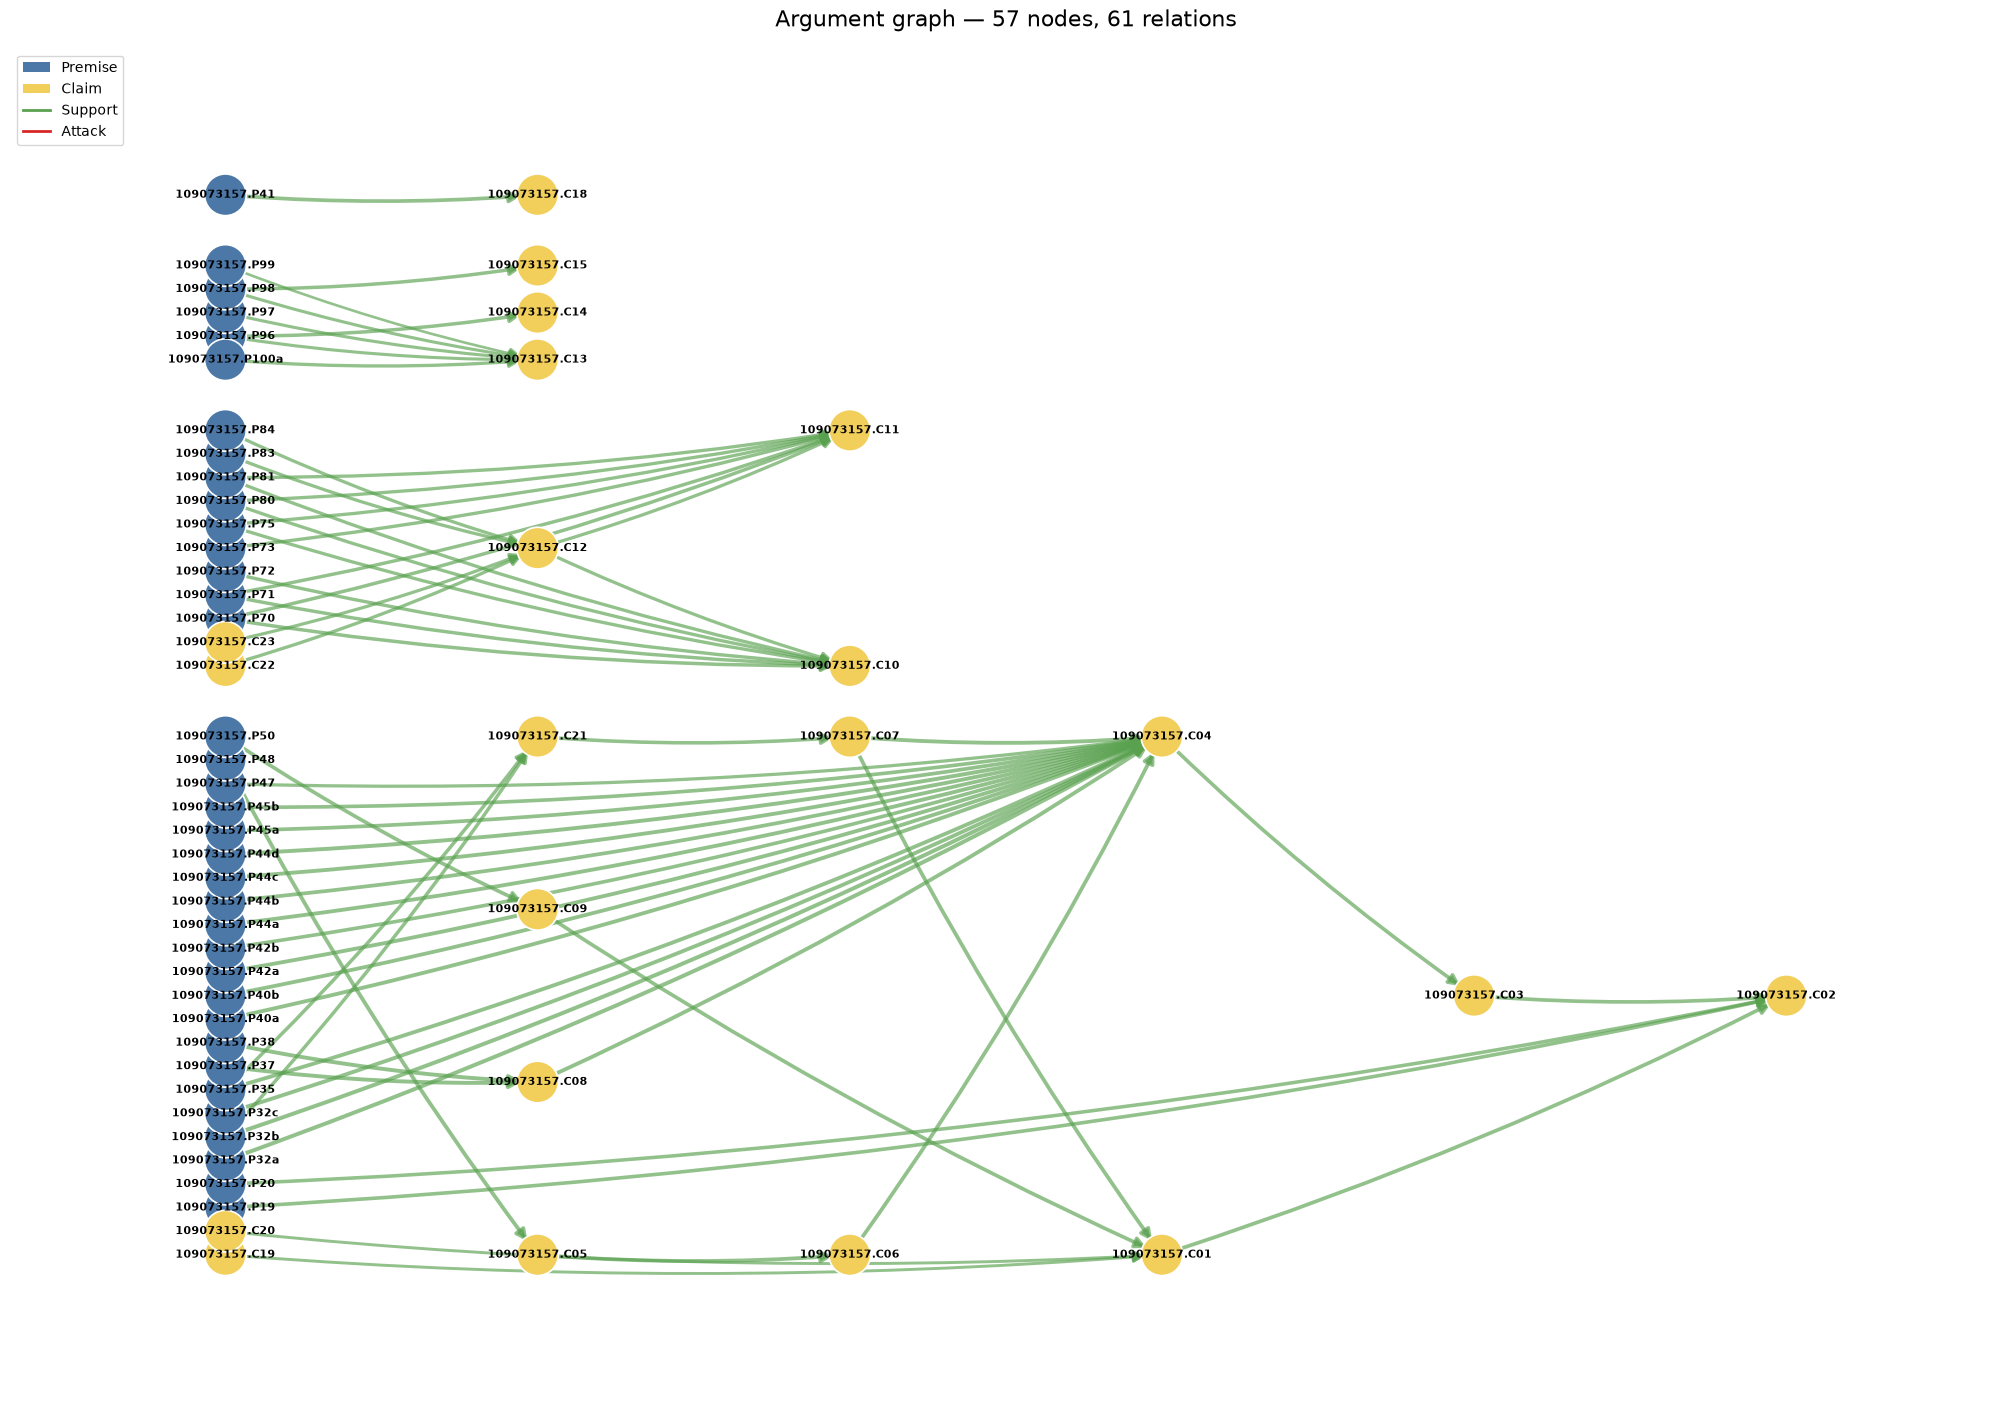

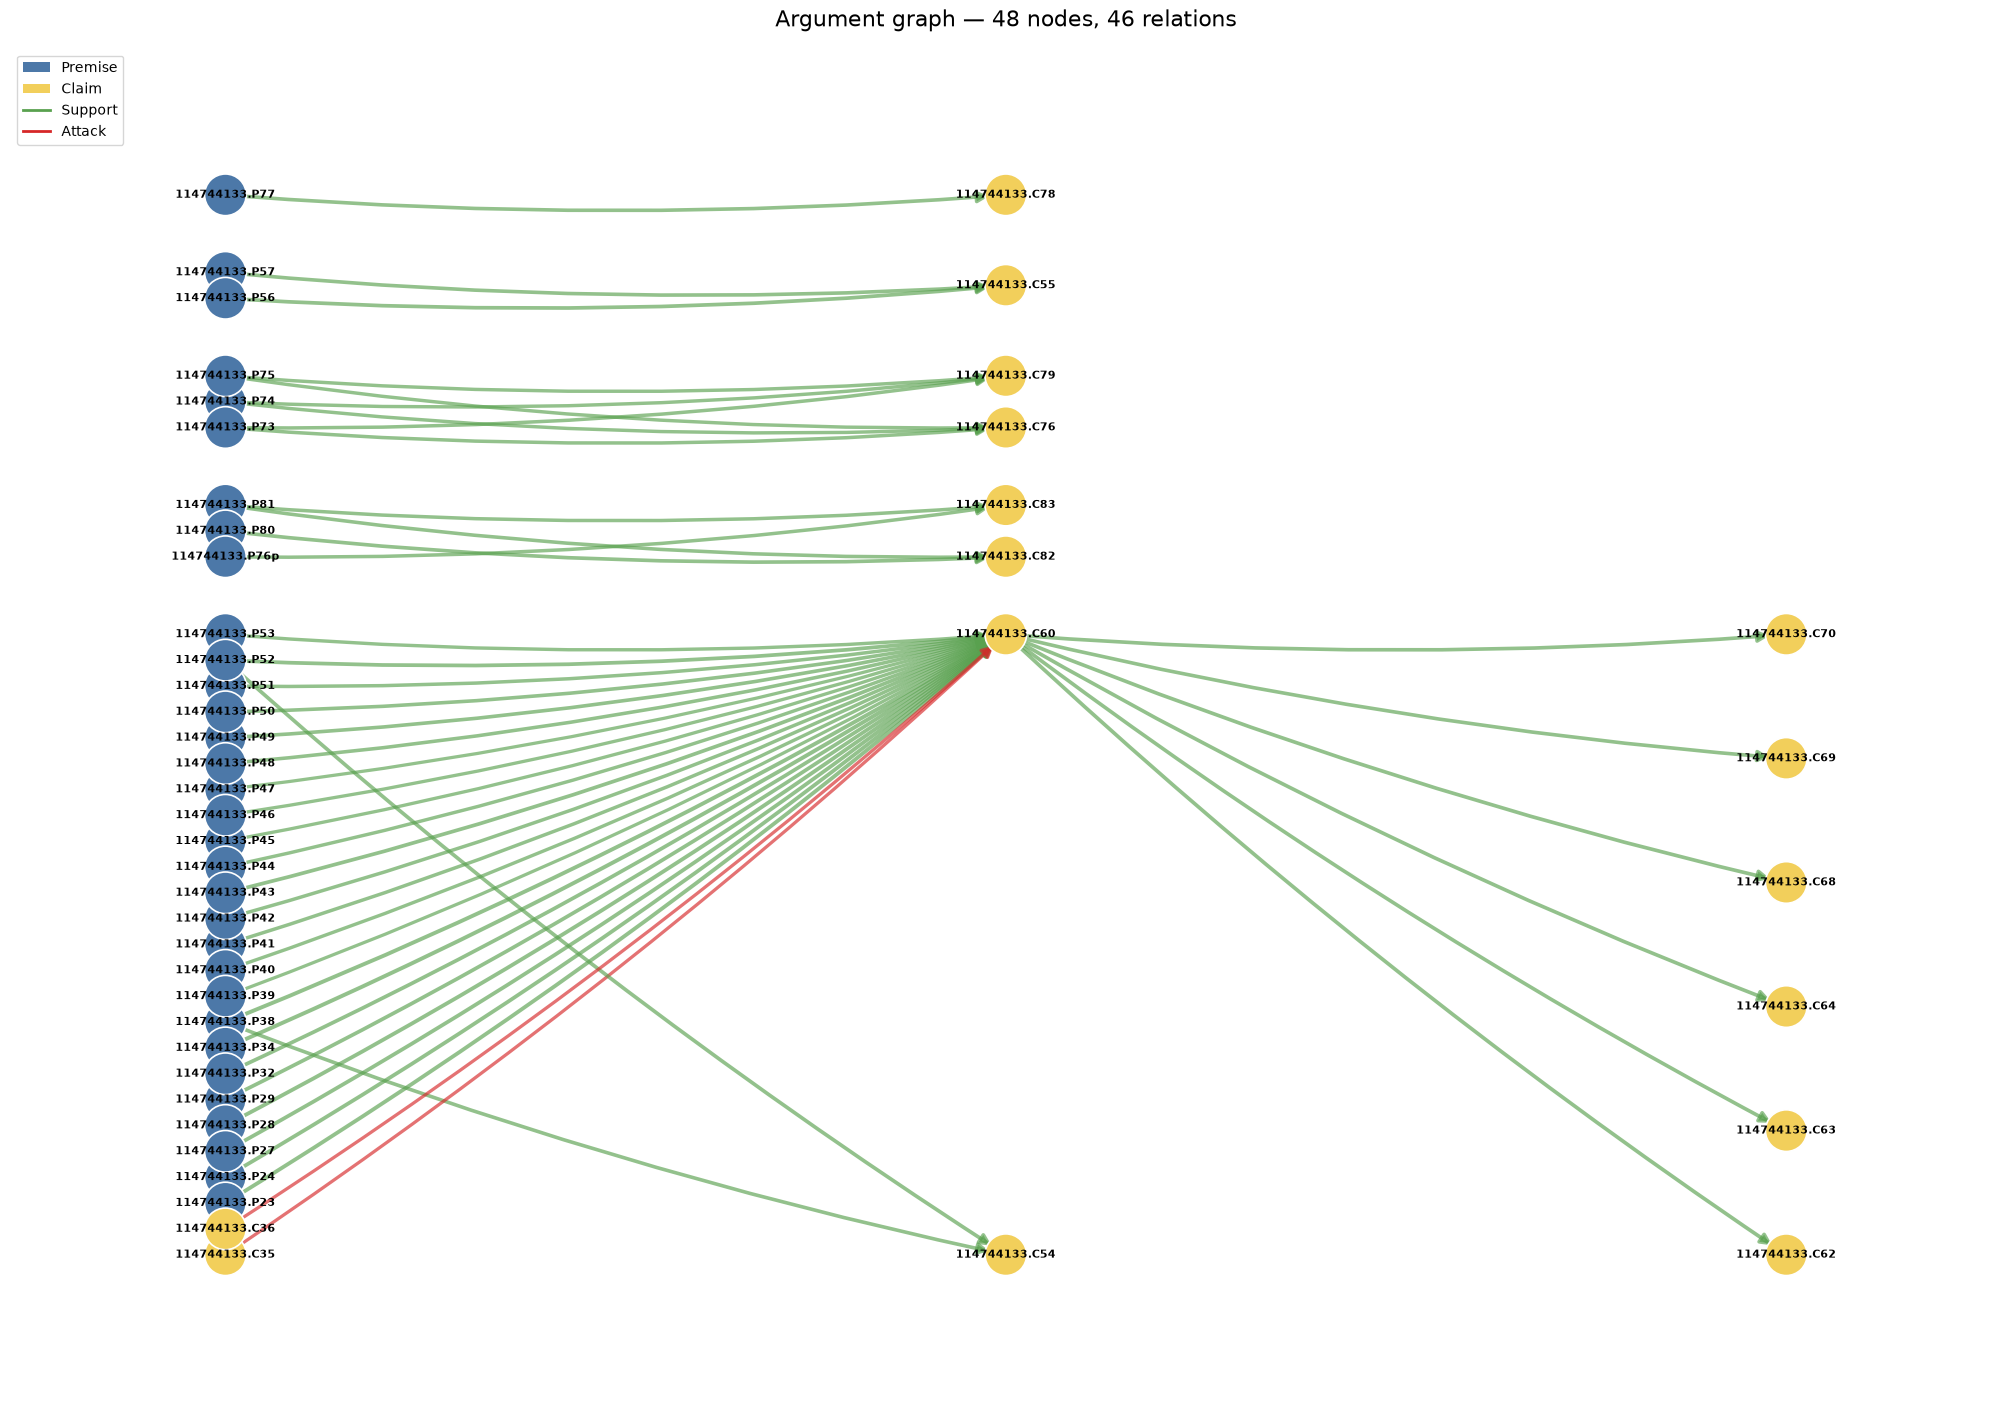

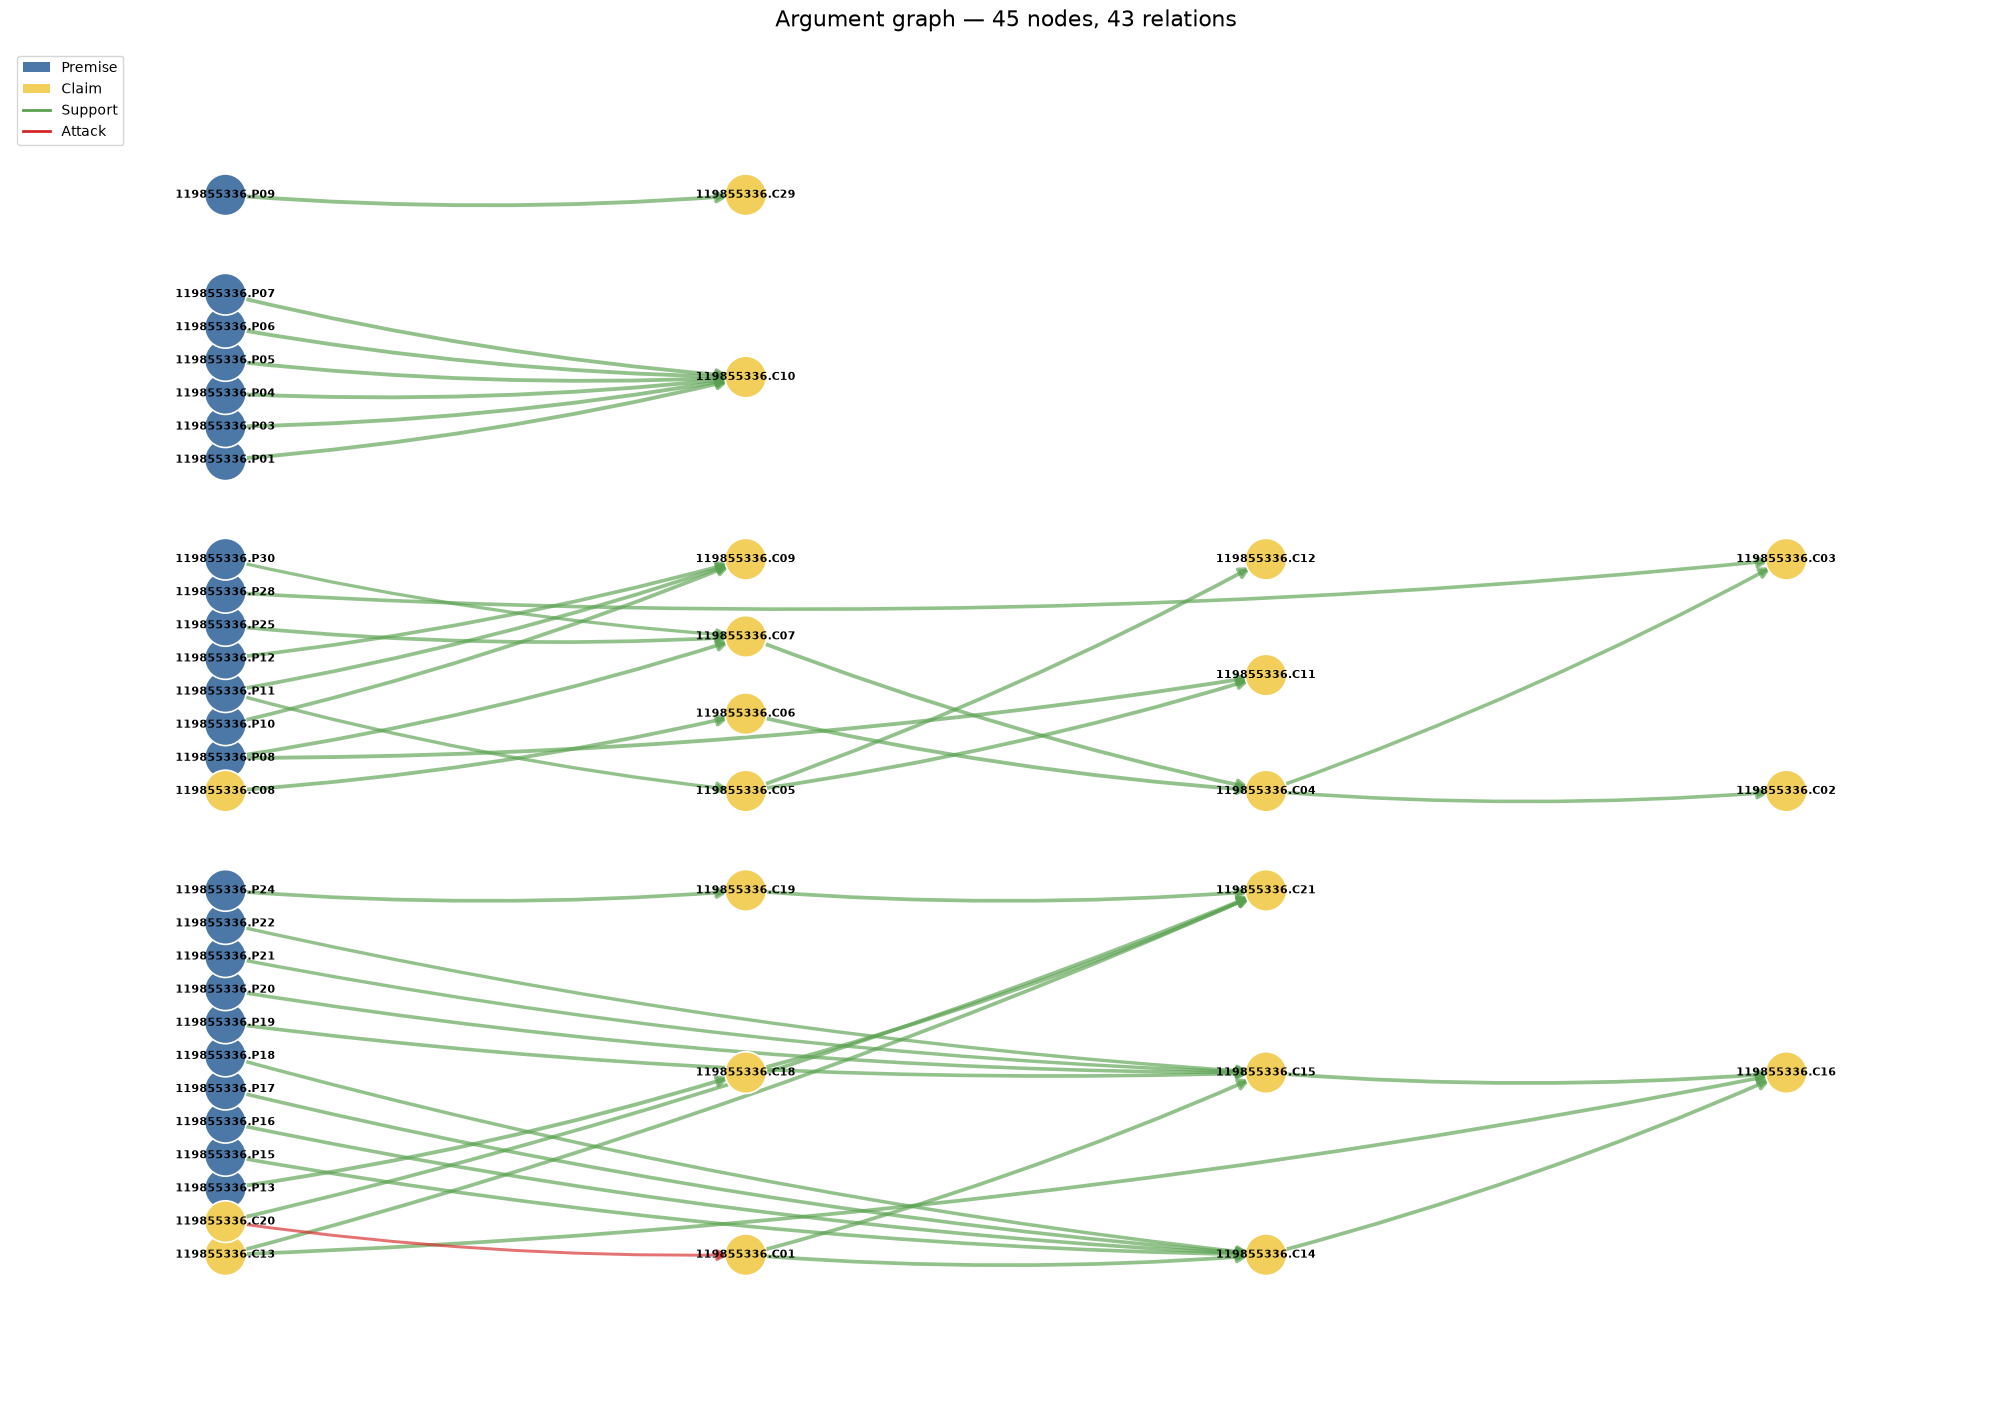

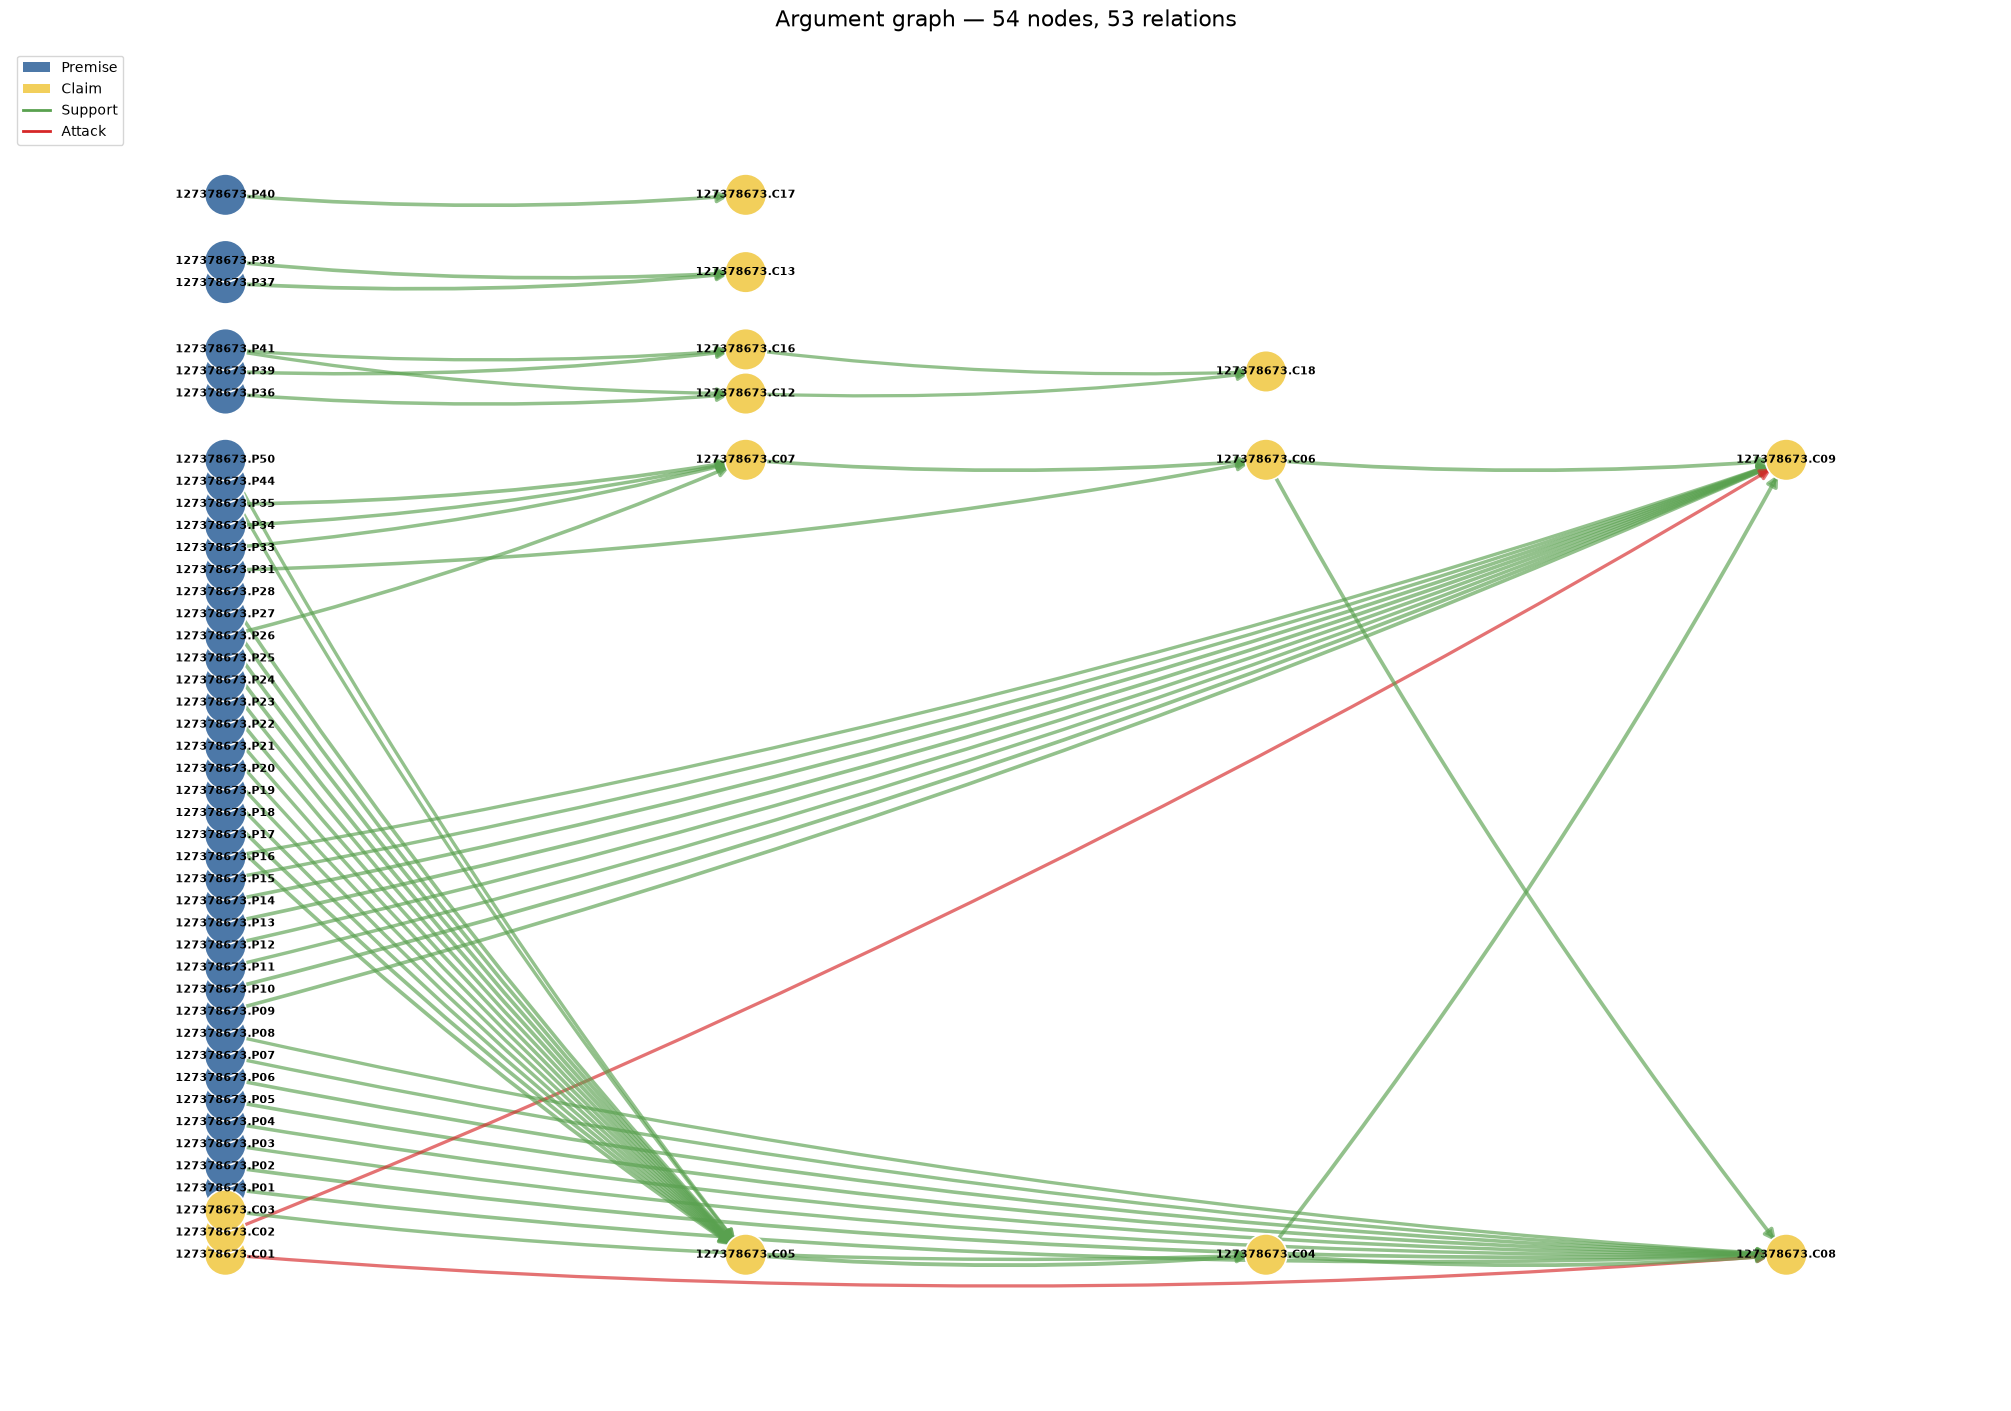

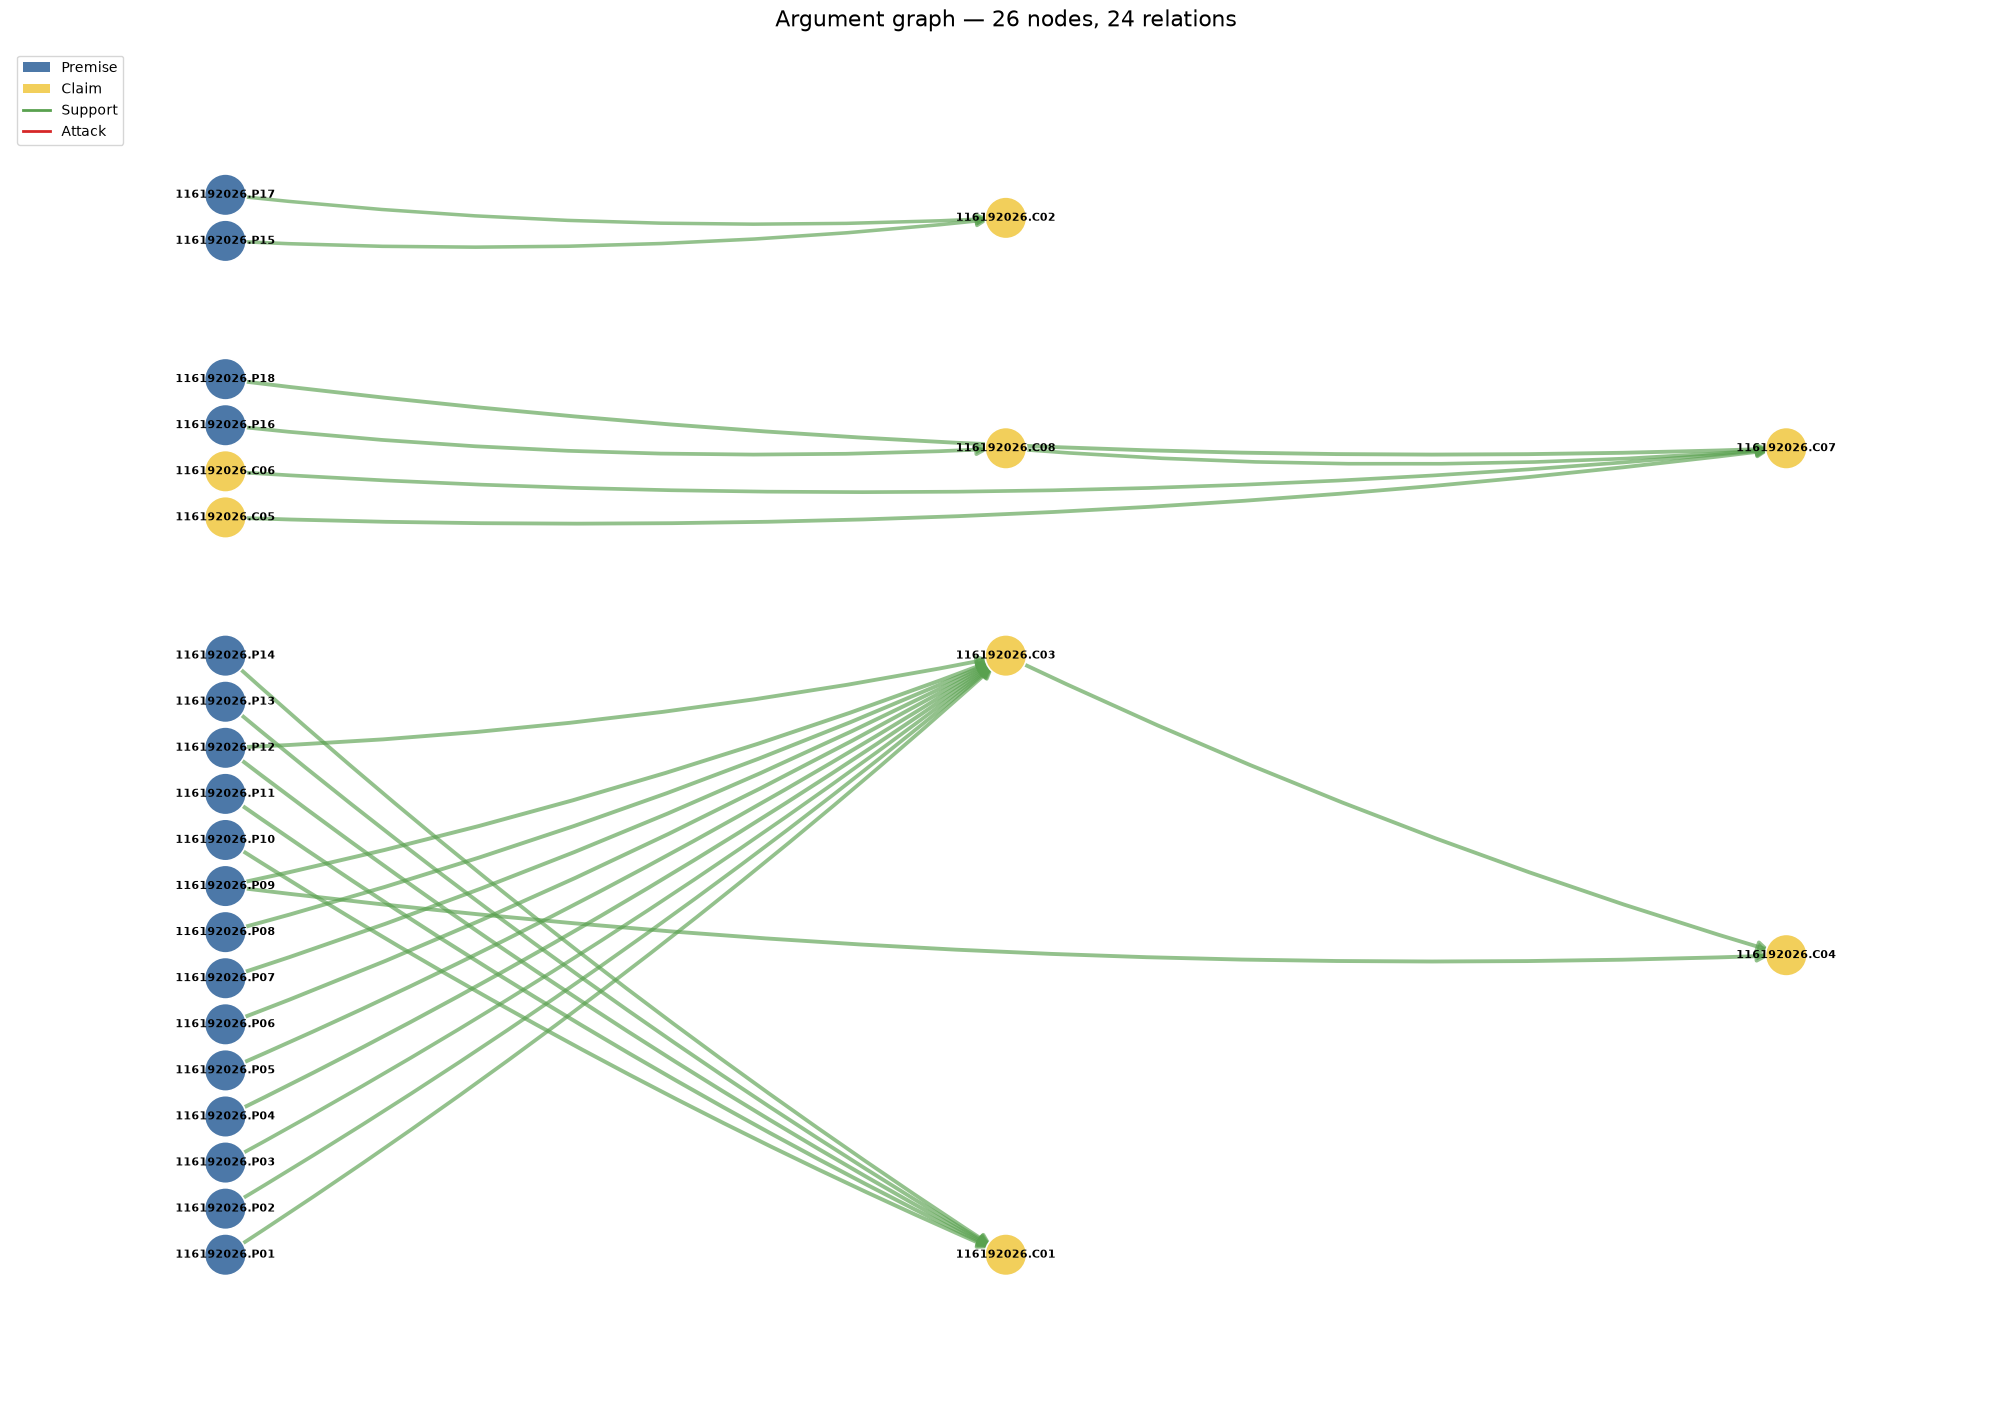

In [28]:
visualize_graph(case_1_G)
visualize_graph(case_2_G)
visualize_graph(case_3_G)
visualize_graph(case_4_G)
visualize_graph(case_5_G)

## Cross-graph similarity

In [32]:
from legal_data_doc_parts.isorank.isorank_emb import cross_graph_similarity

In [33]:
def transition_matrix(A):
    degree = A.sum(axis=1)
    degree[degree == 0] = 1
    return A / degree[:, None]

In [34]:
def generate_type_mask(G1: nx.Graph, G2: nx.Graph):
    mask = np.zeros(shape=(G1.number_of_nodes(), G2.number_of_nodes()))
    for i, u in enumerate(G1.nodes):
        for j, v in enumerate(G2.nodes):
            if G1.nodes[u]["arg_type"] == G2.nodes[v]["arg_type"]:
                mask[i, j] = 1
    return mask

In [35]:
mask = np.zeros(shape=(case_1_G.number_of_nodes(), case_5_G.number_of_nodes()))
for i, u in enumerate(case_1_G.nodes):
    for j, v in enumerate(case_5_G.nodes):
        if case_1_G.nodes[u]["arg_type"] == case_5_G.nodes[v]["arg_type"]:
            mask[i, j] = 1

In [37]:
def top_matches(
    G1: nx.Graph,
    G2: nx.Graph,
    S: np.ndarray,
    top_k: int = 10,
    same_type_only: bool = True,
):
    """Return up to top_k candidates per source node, ranked by similarity."""
    nodes1 = list(G1.nodes)
    nodes2 = list(G2.nodes)

    if S.shape != (len(nodes1), len(nodes2)):
        raise ValueError("S must have one row per G1 node and one column per G2 node")
    if not isinstance(top_k, (int, np.integer)) or top_k < 0:
        raise ValueError("top_k must be a non-negative integer")

    results = []
    for i, node1 in enumerate(nodes1):
        type1 = G1.nodes[node1].get("arg_type")
        candidates = []

        for j, node2 in enumerate(nodes2):
            type2 = G2.nodes[node2].get("arg_type")
            if same_type_only and (type1 is None or type2 is None or type1 != type2):
                continue

            candidates.append({
                "graph1_node": node1,
                "graph1_text": G1.nodes[node1].get("text"),
                "graph1_type": type1,
                "graph2_node": node2,
                "graph2_text": G2.nodes[node2].get("text"),
                "graph2_type": type2,
                "similarity": float(S[i, j]),
            })

        candidates.sort(key=lambda candidate: candidate["similarity"], reverse=True)
        for rank, candidate in enumerate(candidates[:top_k], start=1):
            results.append({**candidate, "rank": rank})

    return results

## Building global matrix
This would represent global similarity graph `H`

In [38]:
import itertools

In [39]:
sizes = [case.number_of_nodes() for case in cases]
sizes

[87,
 132,
 30,
 27,
 51,
 30,
 38,
 47,
 55,
 61,
 28,
 47,
 14,
 36,
 25,
 38,
 32,
 28,
 26,
 25,
 26,
 1,
 4,
 66,
 59,
 45,
 28,
 26,
 38,
 32,
 40,
 30,
 34,
 38,
 34,
 30,
 39,
 37,
 55,
 32,
 55,
 53,
 60,
 111,
 44,
 15,
 33,
 37,
 49,
 77,
 66,
 5,
 43,
 39,
 33,
 44,
 40,
 15,
 38,
 24,
 20,
 37,
 18,
 48,
 20,
 39,
 27,
 37,
 42,
 59,
 32,
 36,
 2,
 62,
 33,
 39,
 71,
 63,
 3,
 93,
 31,
 32,
 67,
 21,
 45,
 5,
 33,
 38,
 93,
 50,
 28,
 36,
 37,
 34,
 43,
 25,
 22,
 36,
 52]

In [40]:
total_length = sum([case.number_of_nodes() for case in cases])
total_length

3941

In [110]:
def build_global_similarity_graph(cases):
    total_length = sum([case.number_of_nodes() for case in cases])
    H = np.zeros(shape=(total_length, total_length))
    print(f"Shape of the global matrix H: {H.shape}")

    enum_cases = enumerate(cases)
    similarities = {}
    for en_case1, en_case2 in itertools.combinations(enum_cases, 2):
        idx1, case_1 = en_case1
        idx2, case_2 = en_case2

        mask = generate_type_mask(case_1, case_2)
        similarities[(idx1, idx2)] = cross_graph_similarity(case_1, case_2, alpha=0.03, mask=mask, unbias_step=False).cpu().numpy()
        mask_np = (
            mask.cpu().numpy()
            if torch.is_tensor(mask)
            else np.asarray(mask)
        )

        assert np.allclose(
            similarities[(idx1, idx2)][~mask_np.astype(bool)],
            0.0,
            atol=1e-8
        )

    sizes = [graph.number_of_nodes() for graph in cases]
    offsets = np.hstack(([0], np.cumsum(sizes)))

    print(f"Sizes of the graphs: {sizes}")
    print(f"Further offsets: {offsets}")

    for (i, j), similarity in similarities.items():
        rows = slice(offsets[i], offsets[i + 1])
        columns = slice(offsets[j], offsets[j + 1])

        H[rows, columns] = similarity
        H[columns, rows] = similarity.T

    return H, offsets

In [111]:
H, offsets = build_global_similarity_graph(cases)

Shape of the global matrix H: (3941, 3941)
Sizes of the graphs: [87, 132, 30, 27, 51, 30, 38, 47, 55, 61, 28, 47, 14, 36, 25, 38, 32, 28, 26, 25, 26, 1, 4, 66, 59, 45, 28, 26, 38, 32, 40, 30, 34, 38, 34, 30, 39, 37, 55, 32, 55, 53, 60, 111, 44, 15, 33, 37, 49, 77, 66, 5, 43, 39, 33, 44, 40, 15, 38, 24, 20, 37, 18, 48, 20, 39, 27, 37, 42, 59, 32, 36, 2, 62, 33, 39, 71, 63, 3, 93, 31, 32, 67, 21, 45, 5, 33, 38, 93, 50, 28, 36, 37, 34, 43, 25, 22, 36, 52]
Further offsets: [   0   87  219  249  276  327  357  395  442  497  558  586  633  647
  683  708  746  778  806  832  857  883  884  888  954 1013 1058 1086
 1112 1150 1182 1222 1252 1286 1324 1358 1388 1427 1464 1519 1551 1606
 1659 1719 1830 1874 1889 1922 1959 2008 2085 2151 2156 2199 2238 2271
 2315 2355 2370 2408 2432 2452 2489 2507 2555 2575 2614 2641 2678 2720
 2779 2811 2847 2849 2911 2944 2983 3054 3117 3120 3213 3244 3276 3343
 3364 3409 3414 3447 3485 3578 3628 3656 3692 3729 3763 3806 3831 3853
 3889 3941]


In [112]:
offsets

array([   0,   87,  219,  249,  276,  327,  357,  395,  442,  497,  558,
        586,  633,  647,  683,  708,  746,  778,  806,  832,  857,  883,
        884,  888,  954, 1013, 1058, 1086, 1112, 1150, 1182, 1222, 1252,
       1286, 1324, 1358, 1388, 1427, 1464, 1519, 1551, 1606, 1659, 1719,
       1830, 1874, 1889, 1922, 1959, 2008, 2085, 2151, 2156, 2199, 2238,
       2271, 2315, 2355, 2370, 2408, 2432, 2452, 2489, 2507, 2555, 2575,
       2614, 2641, 2678, 2720, 2779, 2811, 2847, 2849, 2911, 2944, 2983,
       3054, 3117, 3120, 3213, 3244, 3276, 3343, 3364, 3409, 3414, 3447,
       3485, 3578, 3628, 3656, 3692, 3729, 3763, 3806, 3831, 3853, 3889,
       3941])

In [113]:
H

array([[0.        , 0.        , 0.        , ..., 0.76516736, 0.71415669,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.74492764, 0.69910622,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.79507703, 0.78633708,
        0.        ],
       ...,
       [0.76516736, 0.74492764, 0.79507703, ..., 0.        , 0.        ,
        0.        ],
       [0.71415669, 0.69910622, 0.78633708, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(3941, 3941))

## Building a candidate star around the node

In [45]:
_a = [[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]]
a = np.array(_a, dtype=np.int32)
for x in range(a.shape[0]):
    print(x)

0
1
2
3


In [114]:
max_nodes_idx = np.argmax(H, axis=0)
stars = max_nodes_idx.reshape(-1, 1)
print(stars)

[[3213]
 [3213]
 [3416]
 ...
 [2125]
 [ 759]
 [2300]]


In [115]:
def candidate_stars(H, beta: float):
    stars = {}

    for row_idx, row in enumerate(H):
        w_max = row.max()
        threshold = beta * w_max

        candidates = np.flatnonzero(row >= threshold)

        stars[row_idx] = candidates

    return stars

In [116]:
candidates = candidate_stars(H, 0.98)

In [117]:
candidates

{0: array([3213]),
 1: array([3213]),
 2: array([1253, 3416]),
 3: array([3416]),
 4: array([2571]),
 5: array([3470, 3639]),
 6: array([ 249,  255,  973, 1324]),
 7: array([  88,   92,   96,  100,  104,  108,  112,  116,  120,  124,  170,
         174,  178,  182,  186,  190,  586,  633, 1151, 1612, 1613, 1614,
        1615, 1616, 1617, 1741, 1749, 2031, 2032, 2033, 2091, 2156, 2432,
        2614, 2811, 3454, 3486, 3488, 3534, 3536, 3831]),
 8: array([ 781,  966, 1019, 1153, 1798, 1825, 2031, 2032, 2033, 2034, 2036,
        2037, 2040, 2042, 2044, 2046, 2052, 2054, 2056, 2057]),
 9: array([  98,  102,  106,  110,  114,  118,  122,  126,  315,  422,  783,
        1167, 1336, 1351, 1459, 1486, 1641, 1768, 1769, 1806, 1807, 1916,
        2065, 2115, 2220]),
 10: array([1337, 2696, 3865]),
 11: array([ 205,  259,  411, 1185, 1298, 1555, 1841, 2005, 2095, 2698, 2825,
        2855, 2885, 3135, 3175, 3490, 3702, 3773]),
 12: array([ 637, 1156, 1341, 1860, 2699, 3629, 3768]),
 13: array([1337

In [118]:
def star_weight(H, center, candidates):
    nodes = np.hstack(([center], candidates)).astype(int)
    # print(f"Nodes {nodes}")
    H_star = H[np.ix_(nodes, nodes)]
    return np.triu(H_star, k=1).sum()

In [119]:
scores = {
    center: star_weight(H, center, candidates)
    for center, candidates in candidates.items()
}
order = sorted(scores, key=scores.get, reverse=True)

In [120]:
scores, order

({0: np.float64(0.9387655854225159),
  1: np.float64(0.9294044971466064),
  2: np.float64(2.8070271015167236),
  3: np.float64(0.9429894089698792),
  4: np.float64(0.9182045459747314),
  5: np.float64(2.6247841119766235),
  6: np.float64(8.140387892723083),
  7: np.float64(649.6139749288559),
  8: np.float64(105.56501311063766),
  9: np.float64(268.0246939063072),
  10: np.float64(5.700974106788635),
  11: np.float64(150.37300217151642),
  12: np.float64(25.64286756515503),
  13: np.float64(5.69998174905777),
  14: np.float64(150.33897614479065),
  15: np.float64(25.64286756515503),
  16: np.float64(99.94004321098328),
  17: np.float64(9.584448099136353),
  18: np.float64(5.686597764492035),
  19: np.float64(0.9315276145935059),
  20: np.float64(2.6044466495513916),
  21: np.float64(5.0973705649375916),
  22: np.float64(4.924720048904419),
  23: np.float64(4.269914984703064),
  24: np.float64(47.99104642868042),
  25: np.float64(116.87075757980347),
  26: np.float64(0.9521432518959045)

In [121]:
def rank_stars(H, stars):
    scores = {
        center: star_weight(H, center, candidates)
        for center, candidates in candidates.items()
    }
    order = sorted(scores, key=scores.get, reverse=True)
    return scores, order

Extracting $H^{\star}_i$

In [122]:
def induce_star(
    H: np.ndarray,
    center: int,
    candidates: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:

    nodes = np.asarray(candidates, dtype=int).ravel()

    # assert center in nodes, "Center must be included in candidate star"
    # assert len(nodes) == len(np.unique(nodes)), "Duplicate nodes in star"

    H_star = H[np.ix_(nodes, nodes)]

    return nodes, H_star

In [123]:
stars = []
for row, candidates in candidates.items():
    stars.append(induce_star(H, row, candidates))

In [124]:
star_3_ex = stars[3] # example
star_3_ex

(array([3416]), array([[0.]]))

In [125]:
H_star_3_ex = star_3_ex[1] # getting the matrix of similarities for the given star

In [126]:
degree_3 = H_star_3_ex.sum(axis=1)
P = H_star_3_ex / degree_3[:, None]

/tmp/ipykernel_969259/2216205792.py:2: RuntimeWarning: invalid value encountered in divide
  P = H_star_3_ex / degree_3[:, None]


In [127]:
def lazy_random_walk_recombination(H_star):
    degree = H_star.sum(axis=1)
    P = np.zeros_like(H_star, dtype=float)
    nonzero = degree > 0

    P[nonzero] = (
        H_star[nonzero] / degree[nonzero, None]
    )

    W = 0.5 * (
        np.eye(H_star.shape[0]) + P
    )
    return W, degree

In [128]:
W_ex_3, degree_ex_3 = lazy_random_walk_recombination(H_star_3_ex)

print("Degree:")
print(degree_ex_3)

print("W:")
print(W_ex_3)

print("Row sums:")
print(W_ex_3.sum(axis=1))

Degree:
[0.]
W:
[[0.5]]
Row sums:
[0.5]


Personalized PageRank

In [129]:
seed_idx = 0 # intentionally placed the center first

In [130]:
def personalized_pagerank(
        W,
        seed_idx=0,
        gamma: float = 0.15,
        tol=1e-10,
        max_iter=1000,
):
    n = W.shape[0]
    seed = np.zeros(n, dtype=np.float32)
    seed[seed_idx] = 1.0

    p = seed.copy()
    for iteration in range(max_iter):
        p_new = (
            gamma * seed
            + (1 - gamma) * (p @ W)
        )

        delta = np.linalg.norm(p_new - p, ord=1) # abs
        if delta < tol:
            return p_new, iteration + 1

        p = p_new

    return p, max_iter

Check

In [131]:
p, iterations = personalized_pagerank(W_ex_3, seed_idx=0, gamma=0.15)
print("PageRank:")
print(p)
print("Sum:", p.sum())
print("Iterations:", iterations)

PageRank:
[0.26086958]
Sum: 0.26086957565184266
Iterations: 27


Normalization

In [132]:
def normalized_pagerank(p, degree):
    q = np.zeros_like(p)
    valid = degree > 0
    q[valid] = p[valid] / degree[valid]
    q[~valid] = -np.inf
    return q

In [133]:
q = normalized_pagerank(p, degree_ex_3)
order_local = np.argsort(-q)

print("Normalized PPR:")
print(q)

print("Local ordering:")
print(order_local)

Normalized PPR:
[-inf]
Local ordering:
[0]


In [134]:
def conductance(H_star, subset):
    n = H_star.shape[0]
    subset = np.asarray(subset, dtype=int)
    mask = np.zeros(n, dtype=bool)
    mask[subset] = True
    complement = ~mask

    # the rule to filter similarity > 0
    A = (H_star > 0).astype(int)
    np.fill_diagonal(A, 0)
    degree = A.sum(axis=1)

    vol_S = degree[mask].sum()
    vol_bar = degree[complement].sum()

    denominator = min(vol_S, vol_bar)

    if denominator == 0:
        return np.inf

    cut = A[
        np.ix_(mask, complement)
    ].sum()

    return cut / denominator

In [135]:
def sweep_cut(H_star, order_local, seed_idx=0):
    best_phi = np.inf
    best_subset = None
    results = []

    for k in range(1, len(order_local)):
        subset = order_local[:k]
        if seed_idx not in subset:
            continue

        phi = conductance(H_star, subset)
        results.append({
            "k": k,
            "subset": subset.copy(),
            "phi": phi,
        })

        if phi < best_phi:
            best_phi = phi
            best_subset = subset.copy()

    return best_subset, best_phi, results

In [136]:
def spectral_partition_star(
        H,
        center,
        candidates,
        gamma=0.15,
        tol=1e-10,
        max_iter=1000,
):
    nodes, H_star = induce_star(H, center, candidates)
    W, degree = lazy_random_walk_recombination(H_star)
    p, iterations = personalized_pagerank(W, seed_idx=0, gamma=gamma, tol=tol, max_iter=max_iter)
    q = normalized_pagerank(p, degree)
    order_local = np.argsort(-q)
    best_subset, best_phi, sweeps = sweep_cut(H_star, order_local, seed_idx=0)

    if best_subset is None:
        cluster_global = np.array([center], dtype=int)
    else:
        cluster_global = nodes[best_subset]

    return {
        "center": center,
        "nodes": nodes,
        "H_star": H_star,
        "W": W,
        "degree": degree,
        "pagerank": p,
        "normalized_pagerank": q,
        "order_local": order_local,
        "best_subset_local": best_subset,
        "cluster_global": cluster_global,
        "conductance": best_phi,
        "iterations": iterations,
        "sweeps": sweeps
    }

In [137]:
center = 3
candidates = stars[center][0]
candidates = np.hstack(([center], candidates))
result = spectral_partition_star(
    H,
    center,
    candidates,
    gamma=0.15
)

print("Center:", result["center"])
print("Star nodes:", result["nodes"])
print("PPR:", result["pagerank"])
print(
    "Normalized PPR:",
    result["normalized_pagerank"]
)
print(
    "Order:",
    result["order_local"]
)
print(
    "Final S_v*:",
    result["cluster_global"],
    len(result["cluster_global"])
)
print(
    "Conductance:",
    result["conductance"]
)

Center: 3
Star nodes: [   3 3416]
PPR: [0.57500002 0.42500002]
Normalized PPR: [0.60976297 0.45069437]
Order: [0 1]
Final S_v*: [3] 1
Conductance: 1.0


Evaluation

In [138]:
stars

[(array([3213]), array([[0.]])),
 (array([3213]), array([[0.]])),
 (array([1253, 3416]),
  array([[0.       , 0.9311862],
         [0.9311862, 0.       ]])),
 (array([3416]), array([[0.]])),
 (array([2571]), array([[0.]])),
 (array([3470, 3639]),
  array([[0.        , 0.87280715],
         [0.87280715, 0.        ]])),
 (array([ 249,  255,  973, 1324]),
  array([[0.        , 0.        , 0.89129454, 0.88901168],
         [0.        , 0.        , 0.89472669, 0.89323509],
         [0.89129454, 0.89472669, 0.        , 0.93389696],
         [0.88901168, 0.89323509, 0.93389696, 0.        ]])),
 (array([  88,   92,   96,  100,  104,  108,  112,  116,  120,  124,  170,
          174,  178,  182,  186,  190,  586,  633, 1151, 1612, 1613, 1614,
         1615, 1616, 1617, 1741, 1749, 2031, 2032, 2033, 2091, 2156, 2432,
         2614, 2811, 3454, 3486, 3488, 3534, 3536, 3831]),
  array([[0.        , 0.        , 0.        , ..., 0.90947342, 0.90079999,
          0.90300673],
         [0.        , 0.

In [139]:
assigned = set()
clusters = []
for i, [candidates, H_star] in enumerate(stars):
    center = i
    if center in assigned:
        continue

    candidates = stars[center][0]
    candidates = np.hstack(([center], candidates))
    result = spectral_partition_star(
        H,
        center,
        candidates,
        gamma=0.15
    )
    cluster = result["cluster_global"]

    clusters.append({
        "center": center,
        "nodes": cluster,
        "conductance": result["conductance"],
    })

    assigned.update(cluster)

Merging

In [140]:
def stars_compatible(H, cluster_1, cluster_2, beta, node_to_graph: dict) -> bool:
    v1 = int(cluster_1["center"])
    v2 = int(cluster_2["center"])

    if node_to_graph is not None:
        if node_to_graph[v1] != node_to_graph[v2]:
            return False

    S1 = np.asarray(cluster_1["nodes"], dtype=int)
    S2 = np.asarray(cluster_2["nodes"], dtype=int)

    threshold_1 = beta * H[v1].max()
    threshold_2 = beta * H[v2].max()

    members_2 = S2[S2 != v2]
    members_1 = S1[S1 != v1]

    condition_1 = np.all(
        H[v1, members_2] >= threshold_1
    )

    condition_2 = np.all(
        H[v2, members_1] >= threshold_2
    )

    return bool(condition_1 and condition_2)

In [141]:
def merge_compatible_stars(
    clusters: list[dict],
    H: np.ndarray,
    beta: float,
    node_to_graph: dict | None = None,
) -> list[dict]:

    n = len(clusters)

    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra = find(a)
        rb = find(b)

        if ra != rb:
            parent[rb] = ra

    # Check every pair of refined stars
    for i in range(n):
        for j in range(i + 1, n):

            if stars_compatible(
                H,
                clusters[i],
                clusters[j],
                beta,
                node_to_graph=node_to_graph,
            ):
                union(i, j)

    # Collect compatible stars into groups
    groups = {}

    for i in range(n):
        root = find(i)

        groups.setdefault(root, []).append(i)

    merged_clusters = []

    for member_indices in groups.values():

        centers = np.array(
            [
                clusters[i]["center"]
                for i in member_indices
            ],
            dtype=int
        )

        nodes = np.unique(
            np.concatenate(
                [
                    np.asarray(
                        clusters[i]["nodes"],
                        dtype=int
                    )
                    for i in member_indices
                ]
            )
        )

        merged_clusters.append({
            "centers": centers,
            "nodes": nodes,
            "source_clusters": member_indices,
        })

    return merged_clusters

Generating node to graphs

In [142]:
node_to_graph = np.empty(offsets[-1], dtype=int)

for graph_id in range(len(offsets) - 1):
    start = offsets[graph_id]
    end = offsets[graph_id + 1]

    node_to_graph[start:end] = graph_id

In [154]:
merged_clusters = merge_compatible_stars(
    clusters=clusters,
    H=H,
    beta=0.98,
    node_to_graph=node_to_graph,
)

In [155]:
merged_clusters

[{'centers': array([ 0,  1,  2,  3,  4,  5, 19, 20, 26, 27, 29, 30, 37, 38, 39, 41, 46,
         47, 48, 50, 51, 54, 61, 63, 64, 65, 67, 69, 80, 82, 86]),
  'nodes': array([ 0,  1,  2,  3,  4,  5, 19, 20, 26, 27, 29, 30, 37, 38, 39, 41, 46,
         47, 48, 50, 51, 54, 61, 63, 64, 65, 67, 69, 80, 82, 86]),
  'source_clusters': [0,
   1,
   2,
   3,
   4,
   5,
   19,
   20,
   26,
   27,
   29,
   30,
   37,
   38,
   39,
   41,
   46,
   47,
   48,
   50,
   51,
   54,
   61,
   63,
   64,
   65,
   67,
   69,
   80,
   82,
   86]},
 {'centers': array([ 6, 57]),
  'nodes': array([  6,  57, 249]),
  'source_clusters': [6, 57]},
 {'centers': array([ 7, 58]),
  'nodes': array([   7,   58,   88,   92,   96,  100,  104,  108,  112,  116,  120,
          124,  170,  174,  178,  182,  186,  190, 1612, 1613, 1614, 1615,
         1616, 1617, 3536]),
  'source_clusters': [7, 58]},
 {'centers': array([ 8, 59]),
  'nodes': array([   8,   59, 2031, 2032, 2033, 2034, 2036, 2037, 2040, 2042, 2044,
 

In [156]:
sizes = [len(c["nodes"]) for c in clusters]

print("Number of clusters:", len(sizes))
print("Min:", np.min(sizes))
print("Max:", np.max(sizes))
print("Mean:", np.mean(sizes))

unique, counts = np.unique(sizes, return_counts=True)

for size, count in zip(unique, counts):
    print(size, count)

Number of clusters: 2290
Min: 1
Max: 44
Mean: 4.35589519650655
1 747
2 416
3 200
4 173
5 159
6 134
7 89
8 83
9 52
10 41
11 39
12 26
13 17
14 15
15 9
16 8
17 7
18 8
19 8
20 13
21 4
22 2
23 3
24 5
25 5
26 7
27 5
28 5
29 2
30 2
31 2
32 1
33 1
42 1
44 1


## Restoring argument context from global cluster indices

`H` uses the concatenated node order of `cases`. The mapping below preserves that order so cluster node indices can be joined back to document IDs, argument IDs, types, roles, and source text.

In [157]:
def build_global_node_context(cases, matrix: np.ndarray) -> pd.DataFrame:
    """Map every row/column of H to the corresponding graph node and text."""
    records = []

    for graph_index, graph in enumerate(cases):
        for local_node_index, (node_id, attributes) in enumerate(graph.nodes(data=True)):
            node_key = str(node_id)
            document_id, separator, argument_id = node_key.partition(".")
            if not separator:
                document_id = None
                argument_id = node_key

            records.append({
                "global_node_index": len(records),
                "graph_index": graph_index,
                "local_node_index": local_node_index,
                "node_id": node_id,
                "document_id": document_id,
                "argument_id": argument_id,
                "argument_type": attributes.get("arg_type"),
                "argumentative_role": attributes.get("argumentative_role"),
                "text": attributes.get("text"),
            })

    node_context = pd.DataFrame.from_records(records).set_index(
        "global_node_index",
        drop=False,
    )
    expected_shape = (len(node_context), len(node_context))
    if matrix.shape != expected_shape:
        raise ValueError(
            f"H has shape {matrix.shape}, but the node mapping requires {expected_shape}"
        )
    if node_context["text"].isna().any():
        missing = node_context.loc[node_context["text"].isna(), "node_id"].tolist()
        raise ValueError(f"Graph nodes are missing text: {missing}")

    return node_context


def restore_cluster_arguments(
    clustered_result: list[dict],
    node_context: pd.DataFrame,
) -> pd.DataFrame:
    """Restore graph metadata and argument text for every clustered global index."""
    restored = []

    for cluster_id, cluster in enumerate(clustered_result):
        node_indices = np.asarray(cluster["nodes"], dtype=int).ravel()
        invalid = node_indices[
            (node_indices < 0) | (node_indices >= len(node_context))
        ]
        if invalid.size:
            raise IndexError(
                f"Cluster {cluster_id} contains invalid global indices: {invalid.tolist()}"
            )

        centers = cluster.get("centers")
        if centers is None:
            center = cluster.get("center")
            centers = [] if center is None else [center]
        centers = np.asarray(centers, dtype=int).ravel()

        cluster_rows = node_context.loc[node_indices].copy()
        cluster_rows.insert(0, "cluster_id", cluster_id)
        cluster_rows.insert(1, "cluster_size", len(node_indices))
        cluster_rows.insert(
            2,
            "is_center",
            cluster_rows["global_node_index"].isin(centers),
        )
        if "conductance" in cluster:
            cluster_rows.insert(3, "conductance", cluster["conductance"])

        restored.append(cluster_rows)

    if not restored:
        return pd.DataFrame()

    return pd.concat(restored, ignore_index=True)


global_node_context = build_global_node_context(cases, H)
restored_merged_arguments = restore_cluster_arguments(
    merged_clusters,
    global_node_context,
)
merged_cluster_text = {
    cluster_id: group["text"].tolist()
    for cluster_id, group in restored_merged_arguments.groupby(
        "cluster_id",
        sort=True,
    )
}

print(
    f"Restored {len(restored_merged_arguments)} cluster memberships "
    f"across {restored_merged_arguments['cluster_id'].nunique()} merged clusters."
)
restored_merged_arguments[
    [
        "cluster_id",
        "cluster_size",
        "is_center",
        "global_node_index",
        "document_id",
        "argument_id",
        "argument_type",
        "argumentative_role",
        "text",
    ]
].head(50)

Restored 9101 cluster memberships across 1492 merged clusters.


,cluster_id,cluster_size,is_center,global_node_index,document_id,argument_id,argument_type,argumentative_role,text
0,0,31,True,0,116062204,P17,PREMISE,BASE_PREMISE,Відповідно до витягу з наказу військової части...
1,0,31,True,1,116062204,P18,PREMISE,BASE_PREMISE,Відповідно до витягу з наказу військової части...
2,0,31,True,2,116062204,P19,PREMISE,BASE_PREMISE,"Згідно зі ст.ст. 11, 16, 49 Статуту внутрішньо..."
3,0,31,True,3,116062204,P20,PREMISE,BASE_PREMISE,"Відповідно до ст.ст. 1, 4, 6 Дисциплінарного с..."
4,0,31,True,4,116062204,C21,CLAIM,INTERMEDIATE_CONCLUSION,"Проте, рядовий ОСОБА_5 та молодший сержант ОСО..."
5,0,31,True,5,116062204,P22,PREMISE,BASE_PREMISE,"Так, у зв`язку з виконанням завдань за признач..."
6,0,31,True,19,116062204,P34a,PREMISE,BASE_PREMISE,Представник потерпілого у призначене судове за...
7,0,31,True,20,116062204,P34b,PREMISE,BASE_PREMISE,покарання просив призначити на розсуд суду.
8,0,31,True,26,116062204,C37,CLAIM,INTERMEDIATE_CONCLUSION,"Таким чином, суд вважає, що обставини вчинення..."
9,0,31,True,27,116062204,C38,CLAIM,INTERMEDIATE_CONCLUSION,Кримінальне правопорушення передбачене ч.4 ст...


In [172]:
merged_cluster_text[17]

['Суд, шляхом заслуховування пояснень сторін кримінального провадження, переконався, що укладення угод сторонами є добровільним, при цьому судом встановлено, що ОСОБА_5 та ОСОБА_6 повністю усвідомлює зміст угод про визнання винуватості, характер обвинувачення, щодо яких визнають себе винуватими, цілком розуміють свої права, визначені п.1 ч.4 ст.474 КПК України, а також наслідки укладення, затвердження даних угод, передбачені ч. 2 ст. 473 КПК України, та наслідки їх не виконання, передбачені ст. 476 КПК України.',
 'Після роз`яснення ст.63 Конституції України та ст. 18 КПК України, судом встановлено, що ОСОБА_4 визнав свою вину у вчиненні інкримінованого йому кримінального правопорушення за ч. 4 ст. 185 КК України за обставин, викладених вище, цілком розуміє положення ч. 4 ст. 474 КПК України та наслідки невиконання ним угоди, передбачені ст. 476 КПК України, і наслідки умисного невиконання угоди про визнання винуватості, передбачені ст. 389-1 КК України.',
 'З врахуванням вищевказаного